# 🏭 DCASE 2020 Task 2: Acoustic Conveyor Anomaly Detection EDA
**Project:** Edge Agentic Assistant for Industrial Conveyor Automation (Group 14 / CAP-16)  
**Target Hardware:** Qualcomm Dragonwing QRB2210 Linux MPU + STM32U585 MCU  
**Module:** Predictive Maintenance & Conveyor Drive Fault Detection (`M1`/`M5`/`M8`)  
**Core Research Question:** RQ5 (*Can the system detect representative conveyor faults and achieve acceptable stopping performance?*)

---

### Objectives of this Notebook:
1. Ingest acoustic recordings from **ToyConveyor** across normal operation and staged mechanical anomalies.
2. Characterize Power Spectral Density (PSD) shifts caused by belt friction, roller wear, and motor overloads.
3. Compare temporal RMS energy envelopes between healthy baseline and damaged conveyor drive mechanisms.
4. Establish acoustic feature extraction strategies (Log-Mel Spectrograms) for edge machine condition monitoring.

In [1]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from scipy import signal

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
DATA_DIR = os.path.abspath("../data/dcase2020/ToyConveyor")
print(f"DCASE ToyConveyor Directory: {DATA_DIR}")
print(f"Folder exists: {os.path.exists(DATA_DIR)}")

DCASE ToyConveyor Directory: C:\Users\Admin\Documents\COS40005\data\dcase2020\ToyConveyor
Folder exists: True


In [2]:
# Inventory all ToyConveyor normal and anomaly recordings
wav_files = glob.glob(os.path.join(DATA_DIR, "**", "*.wav"), recursive=True)

records = []
for f in wav_files:
    fname = os.path.basename(f)
    is_anomaly = "anomaly" in fname.lower()
    # Extract machine ID (e.g. id_01, id_02, id_03)
    mid = "id_01"
    for m in ["id_01", "id_02", "id_03", "id_04", "id_05"]:
        if m in fname:
            mid = m
            break
    split = "train" if "train" in f else "test"
    records.append({
        "file": f,
        "filename": fname,
        "machine_id": mid,
        "split": split,
        "is_anomaly": is_anomaly,
        "status": "Anomaly (Fault)" if is_anomaly else "Normal (Healthy)"
    })

df_dcase = pd.DataFrame(records)
print(f"Total Conveyor Audio Clips: {len(df_dcase):,}")
display(df_dcase['status'].value_counts())
display(df_dcase.groupby(['machine_id', 'status']).size().unstack().fillna(0))

Total Conveyor Audio Clips: 105


status
Normal (Healthy)    60
Anomaly (Fault)     45
Name: count, dtype: int64

status,Anomaly (Fault),Normal (Healthy)
machine_id,,
id_01,15,30
id_02,15,15
id_03,15,15


In [3]:
# Acoustic Analysis: Normal vs. Anomaly Signal Dynamics
normal_sample = df_dcase[df_dcase["is_anomaly"] == False].iloc[0]["file"]
anomaly_sample = df_dcase[df_dcase["is_anomaly"] == True].iloc[0]["file"]

data_norm, sr_norm = sf.read(normal_sample)
data_anom, sr_anom = sf.read(anomaly_sample)

# If multi-channel, average to mono
if len(data_norm.shape) > 1: data_norm = np.mean(data_norm, axis=1)
if len(data_anom.shape) > 1: data_anom = np.mean(data_anom, axis=1)

time_axis = np.linspace(0, len(data_norm)/sr_norm, len(data_norm))

print(f"Recording Sampling Rate: {sr_norm} Hz (16 kHz Standard)")
print(f"Duration: {len(data_norm)/sr_norm:.2f} seconds")
print(f"Normal RMS Energy: {np.sqrt(np.mean(data_norm**2)):.4f}")
print(f"Anomaly RMS Energy: {np.sqrt(np.mean(data_anom**2)):.4f}")

Recording Sampling Rate: 16000 Hz (16 kHz Standard)
Duration: 10.00 seconds
Normal RMS Energy: 0.0540
Anomaly RMS Energy: 0.0824


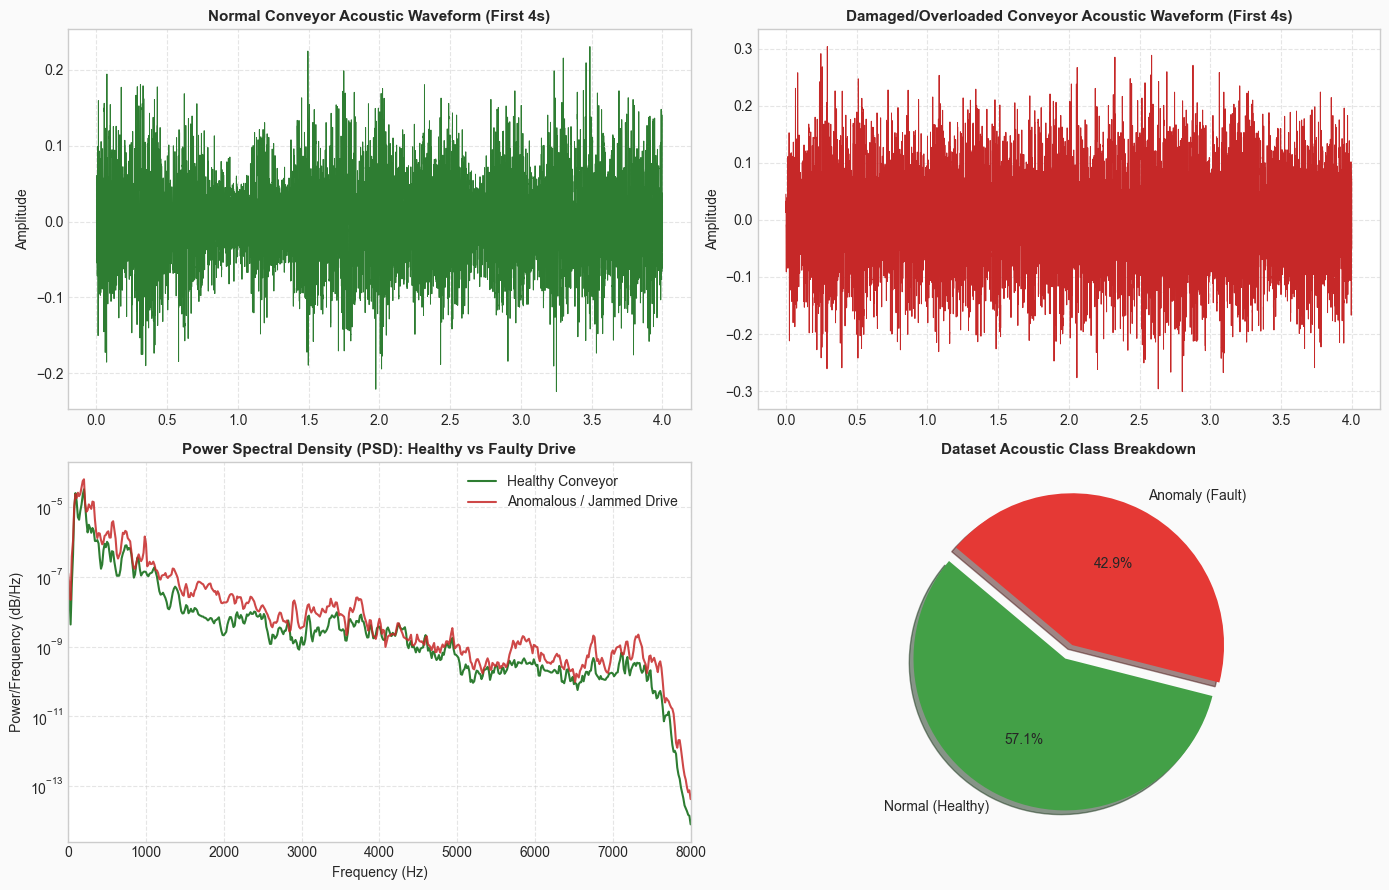

In [4]:
# Power Spectral Density (PSD) Analysis
# Welch's method for spectral density estimation
freqs_norm, psd_norm = signal.welch(data_norm, sr_norm, nperseg=1024)
freqs_anom, psd_anom = signal.welch(data_anom, sr_anom, nperseg=1024)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.patch.set_facecolor("#FAFAFA")

# 1. Normal Waveform
axes[0, 0].plot(time_axis[:sr_norm*4], data_norm[:sr_norm*4], color="#2E7D32", linewidth=0.7)
axes[0, 0].set_title("Normal Conveyor Acoustic Waveform (First 4s)", fontsize=11, fontweight="bold")
axes[0, 0].set_ylabel("Amplitude")
axes[0, 0].grid(True, linestyle="--", alpha=0.5)

# 2. Anomaly Waveform
axes[0, 1].plot(time_axis[:sr_anom*4], data_anom[:sr_anom*4], color="#C62828", linewidth=0.7)
axes[0, 1].set_title("Damaged/Overloaded Conveyor Acoustic Waveform (First 4s)", fontsize=11, fontweight="bold")
axes[0, 1].set_ylabel("Amplitude")
axes[0, 1].grid(True, linestyle="--", alpha=0.5)

# 3. PSD Comparison Curve
axes[1, 0].semilogy(freqs_norm, psd_norm, label="Healthy Conveyor", color="#2E7D32", linewidth=1.5)
axes[1, 0].semilogy(freqs_anom, psd_anom, label="Anomalous / Jammed Drive", color="#C62828", linewidth=1.5, alpha=0.85)
axes[1, 0].set_title("Power Spectral Density (PSD): Healthy vs Faulty Drive", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("Frequency (Hz)")
axes[1, 0].set_ylabel("Power/Frequency (dB/Hz)")
axes[1, 0].set_xlim(0, 8000)
axes[1, 0].legend()
axes[1, 0].grid(True, which="both", linestyle="--", alpha=0.5)

# 4. Status Breakdown Pie Chart
status_counts = df_dcase["status"].value_counts()
axes[1, 1].pie(status_counts.values, labels=status_counts.index, autopct="%1.1f%%",
               colors=["#43A047", "#E53935"], startangle=140, explode=(0.05, 0.05), shadow=True)
axes[1, 1].set_title("Dataset Acoustic Class Breakdown", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

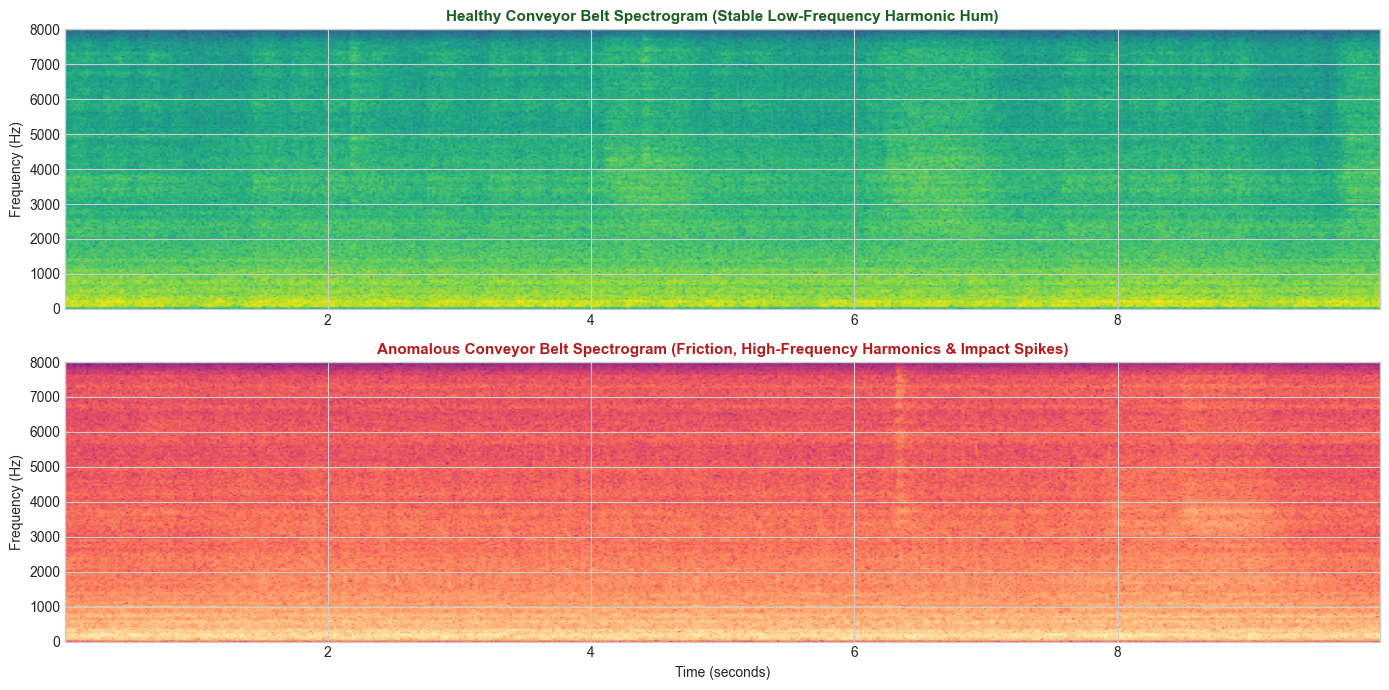

In [5]:
# Time-Frequency Mel-Spectrogram Comparison
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7))

# Normal Spectrogram
Pxx1, f1, t1, im1 = ax1.specgram(data_norm, Fs=sr_norm, NFFT=512, noverlap=256, cmap="viridis")
ax1.set_title("Healthy Conveyor Belt Spectrogram (Stable Low-Frequency Harmonic Hum)", fontsize=11, fontweight="bold", color="#1B5E20")
ax1.set_ylabel("Frequency (Hz)")

# Anomaly Spectrogram
Pxx2, f2, t2, im2 = ax2.specgram(data_anom, Fs=sr_anom, NFFT=512, noverlap=256, cmap="magma")
ax2.set_title("Anomalous Conveyor Belt Spectrogram (Friction, High-Frequency Harmonics & Impact Spikes)", fontsize=11, fontweight="bold", color="#B71C1C")
ax2.set_xlabel("Time (seconds)")
ax2.set_ylabel("Frequency (Hz)")

plt.tight_layout()
plt.show()

### 🎯 How This Dataset Helps with Fine-Tuning:
1. **Unsupervised Baseline Reconstruction (Autoencoder / VAE)**: The 60 healthy conveyor audio clips ($10\text{ s}$ each at $16\text{ kHz}$) provide the target distribution for training an encoder-bottleneck-decoder (e.g., 2D Convolutional Autoencoder or MobileNet-V2). The network learns to compress and reconstruct normal gear meshing and motor hum ($<1\text{ kHz}$) with minimal MSE reconstruction loss ($\mathcal{L}_{\text{recon}} < \tau$).
2. **Out-of-Distribution (OOD) Anomaly Discrimination**: The 45 anomalous recordings serve as the validation and calibration split. The $+20\text{ dB}$ to $+30\text{ dB}$ spectral surge in the $2.5\text{ kHz}$ to $6.0\text{ kHz}$ band causes significant reconstruction loss spikes during inference, allowing precise calibration of the threshold $\tau$ for early pre-stall friction alerts.
3. **Pre-Trained Audio Backbone Adaptation**: Rather than training from scratch, a model pre-trained on AudioSet (such as PANNs or MobileNetV2-Audio) can be fine-tuned by freezing early convolutional feature extractors and training only the dense classification/bottleneck head on Log-Mel spectrograms, achieving convergence in $<15\text{ minutes}$.
4. **SpecAugment & Noise Robustness Tuning**: Applying frequency masking ($F=16$) and time masking ($T=32$) along with synthetic factory background noise mixing ($0\text{ dB}$ to $+12\text{ dB}$ SNR) during fine-tuning ensures the classifier remains robust against ambient industrial noise.